# EDA del grafo de Internet

In [1]:
import networkx as nx

G = nx.read_gml('../fetch/topology-202504-month-PARTIAL.gml')

In [2]:
# Chequeo básico
print(f"El grafo cargado de Internet es conexo: {nx.is_connected(G)}")

El grafo cargado de Internet es conexo: True


In [3]:
# Algunos shortest paths

nx.shortest_path(G, source='1797', target='3356')

['1797', '6057', '3356']

In [4]:
import random
import math
import statistics as stat

def random_sample_file(filename, k):
    with open(filename, 'r') as file:
        lines = file.readlines()
        # Ensure k is not larger than total lines
        sample_size = min(k, len(lines))
        return random.sample(lines, sample_size)

# Usage: get 10 random lines
sample = random_sample_file('../fetch/asns-202504-week1.txt', 10)
source = '1797'
lens = []
for s in sample:
    s = s.strip()
    target = s.lstrip('0')
    sp = nx.shortest_path(G, source=source, target=target)
    ln = len(sp)
    lens.append(ln)
    print(f"Shortest path from source={source} to={target} is {sp} with length {ln}")

#
print(f"Average length: {stat.mean(lens)}")
    
    


Shortest path from source=1797 to=50218 is ['1797', '6057', '9002', '50218'] with length 4
Shortest path from source=1797 to=50186 is ['1797', '6057', '31287', '50186'] with length 4
Shortest path from source=1797 to=144873 is ['1797', '27750', '11537', '23911', '38255', '144873'] with length 6
Shortest path from source=1797 to=45530 is ['1797', '6057', '174', '45530'] with length 4
Shortest path from source=1797 to=53341 is ['1797', '6057', '174', '7018', '53341'] with length 5
Shortest path from source=1797 to=143907 is ['1797', '27750', '11537', '23911', '38255', '143907'] with length 6
Shortest path from source=1797 to=210195 is ['1797', '6057', '174', '9198', '41007', '210195'] with length 6
Shortest path from source=1797 to=214499 is ['1797', '6057', '5603', '214499'] with length 4
Shortest path from source=1797 to=207977 is ['1797', '6057', '3216', '29196', '207977'] with length 5
Shortest path from source=1797 to=200644 is ['1797', '6057', '31133', '200644'] with length 4
Avera

Average length: 3.38
Median length: 3.0


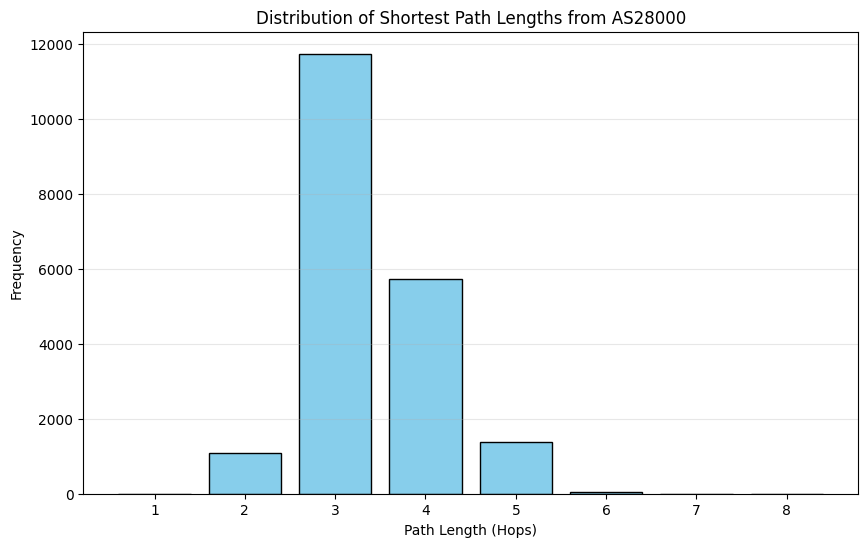

In [5]:
## Histograma

import random
import statistics as stat
import networkx as nx
import matplotlib.pyplot as plt
from collections import Counter

def get_random_sample(filename, k):
    """Memory-efficient way to sample lines from a large file."""
    with open(filename, 'r') as file:
        # Using list(file) is faster for medium files, 
        # but for massive files, consider reservoir sampling.
        lines = file.readlines()
        return random.sample(lines, min(k, len(lines)))

# Configuration
SOURCE_NODE = '28000'
SAMPLE_SIZE = 20000
FILE_PATH = '../fetch/asns-202504-week1.txt'

# 1. Get sample and calculate lengths
sample = get_random_sample(FILE_PATH, SAMPLE_SIZE)
path_lengths = []

for line in sample:
    target = line.strip().lstrip('0')
    try:
        # nx.shortest_path_length is slightly faster than len(nx.shortest_path)
        length = nx.shortest_path_length(G, source=SOURCE_NODE, target=target)
        path_lengths.append(length)
    except nx.NetworkXNoPath:
        print(f"No path found for target: {target}")
    except nx.NodeNotFound:
        continue

# 2. Statistics
if path_lengths:
    print(f"Average length: {stat.mean(path_lengths):.2f}")
    print(f"Median length: {stat.median(path_lengths)}")

    # 3. Build the Histogram
    plt.figure(figsize=(10, 6))
    
    # Calculate bins based on the range of lengths
    bins = range(min(path_lengths), max(path_lengths) + 2)
    
    plt.hist(path_lengths, bins=bins, align='left', rwidth=0.8, color='skyblue', edgecolor='black')
    
    plt.title(f'Distribution of Shortest Path Lengths from AS{SOURCE_NODE}')
    plt.xlabel('Path Length (Hops)')
    plt.ylabel('Frequency')
    plt.xticks(bins[:-1])
    plt.grid(axis='y', alpha=0.3)
    
    plt.show()
else:
    print("No valid paths were found to sample.")

## Muestreando tanto origen como destino

Average length: 3.77
Median length: 4


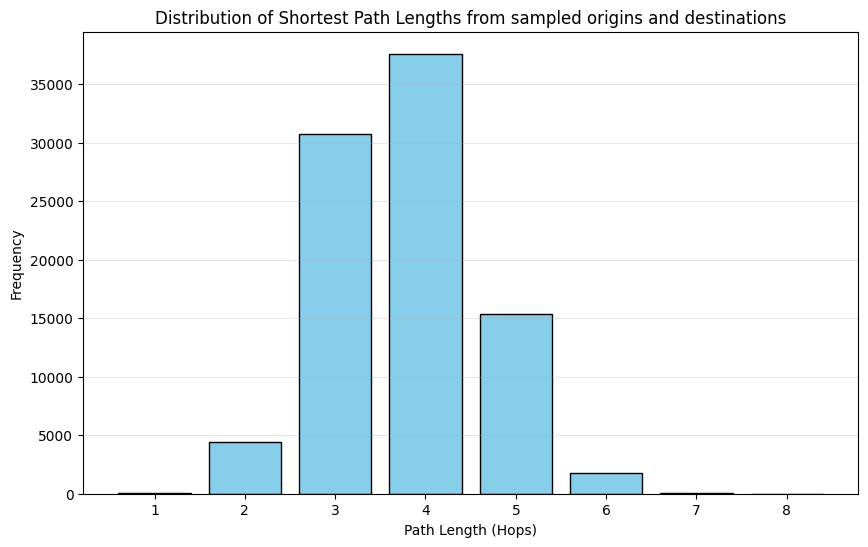

In [6]:
# Also sample the origin

## Histograma

import random
import statistics as stat
import networkx as nx
import matplotlib.pyplot as plt
from collections import Counter

def get_random_sample(filename, k):
    """Memory-efficient way to sample lines from a large file."""
    with open(filename, 'r') as file:
        # Using list(file) is faster for medium files, 
        # but for massive files, consider reservoir sampling.
        lines = file.readlines()
        return random.sample(lines, min(k, len(lines)))

# Configuration
# SOURCE_NODE = '262159'
SAMPLE_SIZE = 300
FILE_PATH = '../fetch/asns-202504-week1.txt'

# 1. Get sample and calculate lengths
sample_origin = get_random_sample(FILE_PATH, SAMPLE_SIZE)
sample = get_random_sample(FILE_PATH, SAMPLE_SIZE)
path_lengths = []

for src in sample_origin:
    SOURCE_NODE = src.strip().lstrip('0')
    for line in sample:
        target = line.strip().lstrip('0')
        if SOURCE_NODE == target:
            continue
        try:
            # nx.shortest_path_length is slightly faster than len(nx.shortest_path)
            length = nx.shortest_path_length(G, source=SOURCE_NODE, target=target)
            path_lengths.append(length)
        except nx.NetworkXNoPath:
            print(f"No path found for target: {target}")
        except nx.NodeNotFound:
            continue

# 2. Statistics
if path_lengths:
    print(f"Average length: {stat.mean(path_lengths):.2f}")
    print(f"Median length: {stat.median(path_lengths)}")

    # 3. Build the Histogram
    plt.figure(figsize=(10, 6))
    
    # Calculate bins based on the range of lengths
    bins = range(min(path_lengths), max(path_lengths) + 2)
    
    plt.hist(path_lengths, bins=bins, align='left', rwidth=0.8, color='skyblue', edgecolor='black')
    
    plt.title(f'Distribution of Shortest Path Lengths from sampled origins and destinations')
    plt.xlabel('Path Length (Hops)')
    plt.ylabel('Frequency')
    plt.xticks(bins[:-1])
    plt.grid(axis='y', alpha=0.3)
    
    plt.show()
else:
    print("No valid paths were found to sample.")

## Correr muchos experimentos

In [7]:
# Also sample the origin

## Histograma

import random
import statistics as stat
import networkx as nx
import matplotlib.pyplot as plt
from collections import Counter

def get_random_sample(filename, k):
    """Memory-efficient way to sample lines from a large file."""
    with open(filename, 'r') as file:
        # Using list(file) is faster for medium files, 
        # but for massive files, consider reservoir sampling.
        lines = file.readlines()
        return random.sample(lines, min(k, len(lines)))

def sample_graph_distribution(N):
    # Configuration
    SAMPLE_SIZE = N
    FILE_PATH = '../fetch/asns-202504-week1.txt'
    
    # 1. Get sample and calculate lengths
    sample_origin = get_random_sample(FILE_PATH, SAMPLE_SIZE)
    sample = get_random_sample(FILE_PATH, SAMPLE_SIZE)
    path_lengths = []
    
    for src in sample_origin:
        SOURCE_NODE = src.strip().lstrip('0')
        for line in sample:
            target = line.strip().lstrip('0')
            if SOURCE_NODE == target:
                continue
            try:
                # nx.shortest_path_length is slightly faster than len(nx.shortest_path)
                length = nx.shortest_path_length(G, source=SOURCE_NODE, target=target)
                path_lengths.append(length)
            except nx.NetworkXNoPath:
                print(f"No path found for target: {target}")
            except nx.NodeNotFound:
                continue

    # 2. Statistics
    if path_lengths:
        avg_length = stat.mean(path_lengths)
        median = stat.median(path_lengths)
        stddev = stat.stdev(path_lengths)
        #print(f"Average length: {stat.mean(path_lengths):.2f}")
        #print(f"Median length: {stat.median(path_lengths)}")   

    return (avg_length, median, stddev)
## end sample graph distribution

## Run many experiments
avgs = []
stds = []
for x in range(10):
    (a,m,s) = sample_graph_distribution(100)
    avgs.append(a)
    stds.append(s)
    print(f"Run {x}: avg len {a}, stdev {s}")
##




Run 0: avg len 3.7387738773877386, stdev 0.865515777028781
Run 1: avg len 3.6612, stdev 0.8452727421376252
Run 2: avg len 3.7821, stdev 0.8984989260049248
Run 3: avg len 3.7631, stdev 0.8288830404281843
Run 4: avg len 3.6452, stdev 0.8678665100278514
Run 5: avg len 3.5906, stdev 0.8146520765336451
Run 6: avg len 3.6978, stdev 0.9216073437259498
Run 7: avg len 3.6584, stdev 0.827513092217748
Run 8: avg len 3.6182618261826183, stdev 0.9088210661070447
Run 9: avg len 3.6634, stdev 0.807072225118456


## Plot the gaussian

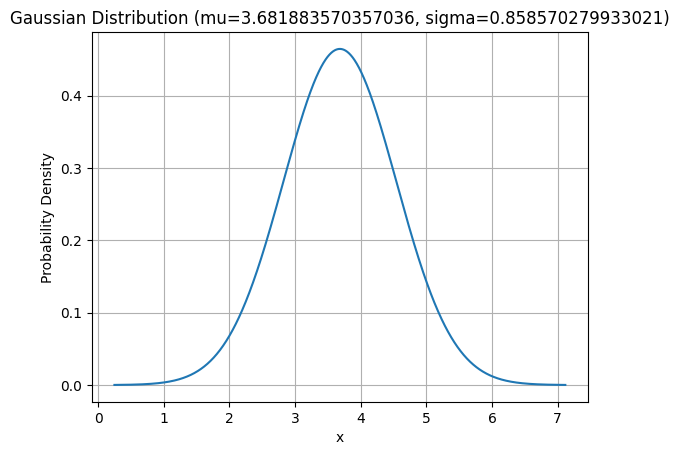

In [8]:
import numpy as np
import matplotlib.pyplot as plt

def plot_gaussian(mu, sigma):
    # Create a range of x values
    x = np.linspace(mu - 4*sigma, mu + 4*sigma, 1000)
    
    # Gaussian (normal distribution) formula
    y = (1 / (sigma * np.sqrt(2 * np.pi))) * np.exp(-0.5 * ((x - mu) / sigma)**2)
    
    # Plot
    plt.figure()
    plt.plot(x, y)
    plt.title(f'Gaussian Distribution (mu={mu}, sigma={sigma})')
    plt.xlabel('x')
    plt.ylabel('Probability Density')
    plt.grid()
    plt.show()

# Example usage
plot_gaussian(mu=stat.mean(avgs), sigma=stat.mean(stds))
